# Metryki oceny modeli klasyfikacyjnych

**Plan notatnika:**
1. Dane i model
2. Macierz pomyłek
3. Accuracy, precision, recall, F1
4. Raport klasyfikacji
5. Pułapka accuracy i model bazowy (baseline)
6. Próg odcięcia a metryki
7. Krzywa ROC i AUC
8. Klasyfikacja wieloklasowa
9. Jak dobrać metrykę
10. Podsumowanie

**Cele:**
- zrozumieć, co mówi każda metryka,
- umieć dobrać metrykę do problemu biznesowego,
- nie oceniać modelu tylko po jednej liczbie (np. samej accuracy).

## 1. Dane i model

Użyjemy zbioru `breast_cancer` ze scikit-learn: 569 guzów piersi opisanych 30 cechami liczbowymi (promień, tekstura, obwód, gładkość itd.), zmierzonymi na zdjęciach biopsji.

**Zmienna celu:** w scikit-learn klasa 0 oznacza guz złośliwy, a 1 – łagodny. Aby „klasą pozytywną” było to, co chcemy wykryć, **odwrócimy etykiety**: `1` = guz **złośliwy** (chcemy go wykryć), `0` = guz łagodny.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report,
                             roc_curve, roc_auc_score)

dane = load_breast_cancer(as_frame=True)
X = dane.data
y = (dane.target == 0).astype(int)   # 1 = guz złośliwy, 0 = guz łagodny

print('Liczba obserwacji i cech:', X.shape)
print(y.value_counts().rename({0: 'łagodny (0)', 1: 'złośliwy (1)'}))

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


Liczba obserwacji i cech: (569, 30)
target
łagodny (0)     357
złośliwy (1)    212
Name: count, dtype: int64


Dzielimy dane na zbiór treningowy i testowy. Argument `stratify=y` zachowuje proporcję klas w obu zbiorach. Cechy mają bardzo różne skale, więc przed modelem dodajemy `StandardScaler` (w jednym `Pipeline`, aby skalowanie uczyło się tylko na zbiorze treningowym).

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)

y_pred = model.predict(X_test)               # klasy (próg 0.5)
y_score = model.predict_proba(X_test)[:, 1]  # prawdopodobieństwo klasy 1 (złośliwy)

## 2. Macierz pomyłek

**Macierz pomyłek** (*confusion matrix*) pokazuje, ile razy model trafił, a ile razy się pomylił. W klasyfikacji binarnej ma 4 pola:

- **TP** (*True Positive*) – model wskazał klasę 1 i miał rację (guz złośliwy rozpoznany jako złośliwy),
- **TN** (*True Negative*) – model wskazał klasę 0 i miał rację,
- **FP** (*False Positive*) – model wskazał klasę 1, a była 0 (**fałszywy alarm**),
- **FN** (*False Negative*) – model wskazał klasę 0, a była 1 (**przeoczenie**).

![Macierz pomyłek](../obrazki/3.2_macierz_pomylek.png)

To punkt wyjścia do wszystkich metryk poniżej. W scikit-learn **wiersze to klasy rzeczywiste, a kolumny to klasy przewidziane**.

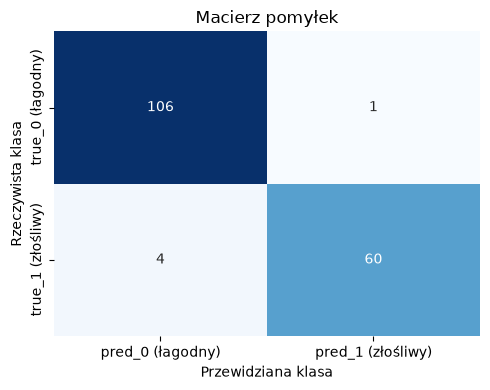

In [3]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['pred_0 (łagodny)', 'pred_1 (złośliwy)'],
            yticklabels=['true_0 (łagodny)', 'true_1 (złośliwy)'])
plt.xlabel('Przewidziana klasa')
plt.ylabel('Rzeczywista klasa')
plt.title('Macierz pomyłek')
plt.tight_layout()
plt.show()

In [4]:
tn, fp, fn, tp = cm.ravel()
print(f'TN (łagodny, rozpoznany jako łagodny):        {tn}')
print(f'FP (łagodny, rozpoznany jako złośliwy):       {fp}')
print(f'FN (złośliwy, rozpoznany jako łagodny):       {fn}')
print(f'TP (złośliwy, rozpoznany jako złośliwy):      {tp}')

TN (łagodny, rozpoznany jako łagodny):        106
FP (łagodny, rozpoznany jako złośliwy):       1
FN (złośliwy, rozpoznany jako łagodny):       4
TP (złośliwy, rozpoznany jako złośliwy):      60


W tym problemie najgroźniejszy jest błąd **FN** – przeoczony nowotwór. Fałszywy alarm (FP) oznacza dodatkowe badania, co jest mniej groźne. Takie rozumowanie decyduje o tym, której metryki szukamy.

Z macierzy można policzyć też wskaźniki błędów:

In [5]:
print(f'False Positive Rate = FP / (FP + TN) = {fp / (fp + tn):.3f}   (odsetek zdrowych błędnie uznanych za chorych)')
print(f'False Negative Rate = FN / (FN + TP) = {fn / (fn + tp):.3f}   (odsetek chorych, których przeoczono)')

False Positive Rate = FP / (FP + TN) = 0.009   (odsetek zdrowych błędnie uznanych za chorych)
False Negative Rate = FN / (FN + TP) = 0.062   (odsetek chorych, których przeoczono)


## 3. Accuracy, precision, recall, F1

### Accuracy (dokładność)

Odsetek wszystkich poprawnych predykcji:

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

Dobra, gdy klasy są podobnie liczne i błędy każdego typu są równie kosztowne. Przy niezrównoważonych klasach może **mylić** (zobacz sekcja 5).

In [ ]:
print('Accuracy (sklearn):', round(accuracy_score(y_test, y_pred), 4))
print('Accuracy (ręcznie):', round((tp + tn) / (tp + tn + fp + fn), 4))

### Precision (precyzja)

Odpowiada na pytanie: **jeśli model wskazał klasę 1, to jak często ma rację?**

$$\text{Precision} = \frac{TP}{TP + FP}$$

Wysoka precision jest ważna, gdy **fałszywy alarm (FP) jest kosztowny** (np. filtr spamu, który nie może wyrzucać ważnych maili).

In [ ]:
print('Precision (sklearn):', round(precision_score(y_test, y_pred), 4))
print('Precision (ręcznie):', round(tp / (tp + fp), 4))

### Recall (czułość)

Odpowiada na pytanie: **jaką część wszystkich rzeczywistych przypadków klasy 1 model wykrył?**

$$\text{Recall} = \frac{TP}{TP + FN}$$

Wysoki recall jest kluczowy, gdy **przeoczenie (FN) jest kosztowne** (np. choroba, oszustwo finansowe).

In [ ]:
print('Recall (sklearn):', round(recall_score(y_test, y_pred), 4))
print('Recall (ręcznie):', round(tp / (tp + fn), 4))

### F1-score

Precision i recall zwykle „ciągną w przeciwne strony” – poprawa jednej często pogarsza drugą. **F1** łączy je w jedną liczbę (średnia harmoniczna):

$$F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

Jest wysokie tylko wtedy, gdy **obie** metryki są wysokie. Przydaje się przy niezrównoważonych klasach.

In [ ]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print('F1 (sklearn):', round(f1_score(y_test, y_pred), 4))
print('F1 (ręcznie):', round(2 * precision * recall / (precision + recall), 4))

## 4. Raport klasyfikacji

`classification_report` zbiera precision, recall i F1 **dla każdej klasy** oraz średnie zbiorcze. To najszybszy sposób na wstępną ocenę modelu. Kolumna `support` to liczba obserwacji danej klasy w zbiorze testowym.

In [6]:
print(classification_report(y_test, y_pred, target_names=['łagodny (0)', 'złośliwy (1)']))

              precision    recall  f1-score   support

 łagodny (0)       0.96      0.99      0.98       107
złośliwy (1)       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



## 5. Pułapka accuracy i model bazowy (baseline)

Weźmy problem, w którym **klasa 1 to tylko 5% danych** (np. wykrywanie oszustw). Zbudujemy dwa modele:
- `DummyClassifier` – „model” bez uczenia się; przy strategii `most_frequent` zawsze zwraca **najczęstszą klasę** ze zbioru treningowego, ignorując cechy,
- zwykłą regresję logistyczną.

`DummyClassifier` to **punkt odniesienia** (*baseline*): każdy sensowny model musi go pokonać.

In [7]:
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier

X_i, y_i = make_classification(n_samples=5000, n_features=10, n_informative=5,
                               weights=[0.95], flip_y=0, class_sep=1.5, random_state=42)
print('Odsetek klasy 1:', y_i.mean())

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_i, y_i, test_size=0.3, random_state=42, stratify=y_i
)

modele = {
    'DummyClassifier (zawsze klasa 0)': DummyClassifier(strategy='most_frequent'),
    'LogisticRegression': LogisticRegression(),
}

wiersze = {}
for nazwa, m in modele.items():
    m.fit(Xi_train, yi_train)
    p = m.predict(Xi_test)
    wiersze[nazwa] = {
        'accuracy': accuracy_score(yi_test, p),
        'precision': precision_score(yi_test, p, zero_division=0),
        'recall': recall_score(yi_test, p),
        'F1': f1_score(yi_test, p),
    }

pd.DataFrame(wiersze).T.round(3)

Odsetek klasy 1: 0.05


,accuracy,precision,recall,F1
DummyClassifier (zawsze klasa 0),0.950,0.000,0.000,0.000
LogisticRegression,0.965,0.739,0.453,0.562


Model „zawsze klasa 0” ma accuracy około **95%**, ale **nie wykrywa żadnego** przypadku klasy 1 (recall = 0), więc jest bezużyteczny. Regresja logistyczna ma tylko nieco wyższą accuracy, a wykrywa już prawie połowę przypadków klasy 1 – różnicę widać dopiero w recall i F1. Wniosek: **accuracy zawsze łączymy z precision i recall**, a model porównujemy z baseline'em.

W naszym zbiorze o nowotworach (klasy w proporcji około 63% / 37%) baseline też ma sporą accuracy:

In [ ]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f'Accuracy baseline (zawsze: łagodny): {accuracy_score(y_test, dummy.predict(X_test)):.3f}')
print(f'Accuracy naszego modelu:             {accuracy_score(y_test, y_pred):.3f}')

## 6. Próg odcięcia a metryki

`predict` używa progu 0,5. Ale model zwraca prawdopodobieństwa (`y_score`), więc możemy próg **zmieniać** i obserwować kompromis między FP i FN. Ponieważ w naszym problemie przeoczenie nowotworu jest gorsze niż fałszywy alarm, warto sprawdzić niższe progi.

In [8]:
wiersze = []
for prog in [0.1, 0.2, 0.3, 0.5, 0.7, 0.9]:
    pred = (y_score >= prog).astype(int)
    wiersze.append({
        'próg': prog,
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'FP (fałszywe alarmy)': int(((pred == 1) & (y_test == 0)).sum()),
        'FN (przeoczenia)': int(((pred == 0) & (y_test == 1)).sum()),
    })

pd.DataFrame(wiersze).set_index('próg').round(3)

,precision,recall,F1,FP (fałszywe alarmy),FN (przeoczenia)
próg,,,,,
0.1,0.900,0.984,0.940,7,1
0.2,0.955,0.984,0.969,3,1
0.3,0.984,0.969,0.976,1,2
0.5,0.984,0.938,0.960,1,4
0.7,1.000,0.922,0.959,0,5
0.9,1.000,0.797,0.887,0,13


Im **niższy próg**, tym wyższy recall (mniej przeoczeń), ale niższa precision (więcej fałszywych alarmów). Im **wyższy próg**, tym odwrotnie. Wybór progu to **decyzja biznesowa**, a nie techniczna.

## 7. Krzywa ROC i AUC

Przy zmianie progu zmieniają się TPR i FPR. **Krzywa ROC** pokazuje je dla **wszystkich** możliwych progów:
- **TPR** (*True Positive Rate*) = recall – jaką część klasy 1 wykrywamy,
- **FPR** (*False Positive Rate*) – jaka część klasy 0 jest błędnie oznaczona jako 1.

**AUC** (*Area Under Curve*) to pole pod krzywą ROC:
- `AUC = 1,0` – model idealny,
- `AUC = 0,5` – model losowy (linia przerywana),
- im wyżej krzywa, tym lepiej model rozróżnia klasy **niezależnie od wybranego progu**.

Krzywą ROC liczymy na **prawdopodobieństwach**, a nie na etykietach 0/1.

In [ ]:
fpr, tpr, progi = roc_curve(y_test, y_score)
auc_wynik = roc_auc_score(y_test, y_score)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Krzywa ROC (AUC = {auc_wynik:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Model losowy')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (recall)')
plt.title('Krzywa ROC')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 8. Klasyfikacja wieloklasowa

Gdy klas jest więcej niż dwie, używamy tych samych idei. Macierz pomyłek ma wtedy wymiar $k \times k$, a precision, recall i F1 liczymy **osobno dla każdej klasy** (traktując ją jako „pozytywną”, a resztę jako „negatywną”), po czym je **uśredniamy**:
- **macro** – zwykła średnia po klasach (każda klasa tak samo ważna),
- **weighted** – średnia ważona liczebnością klas.

Poniżej przykładowe etykiety rzeczywiste i przewidziane dla 3 klas.

Accuracy: 0.724


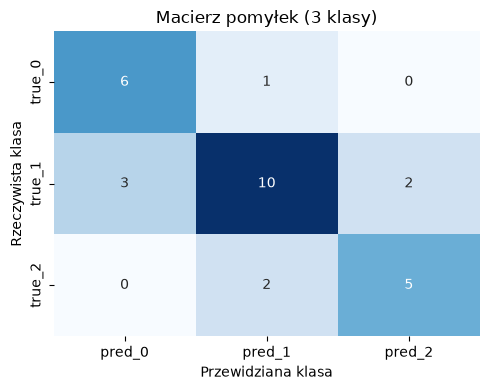

In [9]:
y_true = np.array([1, 0, 1, 2, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 2, 1, 1, 2, 2, 1, 0, 1, 1, 0, 2, 1, 1, 2, 2])
y_hat  = np.array([0, 0, 1, 2, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 2, 1, 2, 1, 2, 1, 0, 2, 1, 0, 1, 1, 1, 2, 2])

print('Accuracy:', round(accuracy_score(y_true, y_hat), 3))

cm3 = confusion_matrix(y_true, y_hat)

plt.figure(figsize=(5, 4))
sns.heatmap(cm3, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['pred_0', 'pred_1', 'pred_2'], yticklabels=['true_0', 'true_1', 'true_2'])
plt.xlabel('Przewidziana klasa')
plt.ylabel('Rzeczywista klasa')
plt.title('Macierz pomyłek (3 klasy)')
plt.tight_layout()
plt.show()

In [10]:
print(classification_report(y_true, y_hat))

              precision    recall  f1-score   support

           0       0.67      0.86      0.75         7
           1       0.77      0.67      0.71        15
           2       0.71      0.71      0.71         7

    accuracy                           0.72        29
   macro avg       0.72      0.75      0.73        29
weighted avg       0.73      0.72      0.72        29



In [11]:
print('F1 macro:   ', round(f1_score(y_true, y_hat, average='macro'), 3))
print('F1 weighted:', round(f1_score(y_true, y_hat, average='weighted'), 3))

F1 macro:    0.726
F1 weighted: 0.723


## 9. Jak dobrać metrykę

| Sytuacja | Co jest groźniejsze | Metryka |
|---|---|---|
| diagnoza choroby, wykrywanie oszustw | przeoczenie (FN) | **recall** |
| filtr spamu, polecanie treści | fałszywy alarm (FP) | **precision** |
| klasy niezrównoważone, liczą się oba błędy | – | **F1** |
| klasy zbliżone liczebnie, błędy równie kosztowne | – | **accuracy** |
| porównanie modeli niezależnie od progu | – | **ROC-AUC** |

## 10. Podsumowanie

1. Nie oceniaj klasyfikatora tylko jedną metryką.
2. **Macierz pomyłek** to najlepszy punkt startu – z niej wynikają wszystkie pozostałe metryki.
3. **Accuracy** bywa mylące przy niezrównoważonych klasach; zawsze porównuj model z **baseline'em** (`DummyClassifier`).
4. **Precision** odpowiada na pytanie „ile alarmów jest prawdziwych?”, a **recall** – „ile przypadków wykryliśmy?”. Wybór zależy od kosztu błędów.
5. **F1** równoważy precision i recall.
6. **Próg odcięcia** pozwala przesuwać równowagę między FP i FN – wybieramy go biznesowo.
7. **ROC-AUC** ocenia zdolność rozróżniania klas niezależnie od progu.
8. Przy wielu klasach metryki liczymy dla każdej klasy i uśredniamy (macro, weighted).